In [22]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc
)
from sklearn.preprocessing import label_binarize
from xgboost import XGBClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [23]:
DATA_PATH = "kolkata_weather_jan_june_2026 (1).csv"
df = pd.read_csv(DATA_PATH)

print("Ukuran dataset:", df.shape)
display(df.head())
print("\nTipe data:")
display(df.dtypes.rename("dtype").to_frame())
print("\nRingkasan statistik:")
display(df.describe(include="all").T)

Ukuran dataset: (1827, 17)


,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude
0,2021-06-30,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,2021-06-30T04:55,2021-06-30T18:25,20837.76,Kolkata,22.5726,88.3639
1,2021-07-01,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,2021-07-01T04:55,2021-07-01T18:25,21439.24,Kolkata,22.5726,88.3639
2,2021-07-02,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,2021-07-02T04:56,2021-07-02T18:25,12291.52,Kolkata,22.5726,88.3639
3,2021-07-03,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,2021-07-03T04:56,2021-07-03T18:25,29486.65,Kolkata,22.5726,88.3639
4,2021-07-04,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,2021-07-04T04:56,2021-07-04T18:25,41145.46,Kolkata,22.5726,88.3639



Tipe data:


,dtype
time,str
weather_code,int64
temperature_2m_mean,float64
temperature_2m_max,float64
temperature_2m_min,float64
precipitation_sum,float64
rain_sum,float64
precipitation_hours,float64
wind_speed_10m_max,float64
wind_gusts_10m_max,float64



Ringkasan statistik:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
time,1827,1827,2021-06-30,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather_code,1827.0,NaN,NaN,NaN,34.143952,28.997216,0.0,3.0,51.0,63.0,65.0
temperature_2m_mean,1827.0,NaN,NaN,NaN,26.26486,4.05022,15.0,23.4,27.4,29.1,35.2
temperature_2m_max,1827.0,NaN,NaN,NaN,31.099234,3.924558,19.6,28.7,31.3,33.3,43.9
temperature_2m_min,1827.0,NaN,NaN,NaN,22.477066,4.847343,10.2,18.6,24.6,26.2,30.6
precipitation_sum,1827.0,NaN,NaN,NaN,5.429119,9.550693,0.0,0.0,0.4,7.35,80.5
rain_sum,1827.0,NaN,NaN,NaN,5.429119,9.550693,0.0,0.0,0.4,7.35,80.5
precipitation_hours,1827.0,NaN,NaN,NaN,4.952928,6.275264,0.0,0.0,2.0,9.0,24.0
wind_speed_10m_max,1827.0,NaN,NaN,NaN,13.782157,5.106847,4.5,10.0,12.6,16.6,44.0
wind_gusts_10m_max,1827.0,NaN,NaN,NaN,30.756596,9.081119,11.5,24.1,29.5,36.0,83.9


In [24]:
# Parse kolom tanggal/waktu dan tampilkan rentang tanggal
df["time"] = pd.to_datetime(df["time"], errors="coerce")
print("Tanggal paling awal:", df["time"].min())
print("Tanggal paling akhir:", df["time"].max())
print("Jumlah baris duplikat:", df.duplicated().sum())
print("\nJumlah missing values per kolom:")
display(df.isna().sum().rename("missing_values").to_frame())

Tanggal paling awal: 2021-06-30 00:00:00
Tanggal paling akhir: 2026-06-30 00:00:00
Jumlah baris duplikat: 0

Jumlah missing values per kolom:


,missing_values
time,0
weather_code,0
temperature_2m_mean,0
temperature_2m_max,0
temperature_2m_min,0
precipitation_sum,0
rain_sum,0
precipitation_hours,0
wind_speed_10m_max,0
wind_gusts_10m_max,0


In [25]:
# Salin data agar dataset mentah tetap tersedia
data = df.copy()

# Pastikan target tersedia, lalu hilangkan baris yang targetnya kosong
data = data.dropna(subset=["weather_code"]).copy()
data["weather_code"] = data["weather_code"].astype(int)

# Fitur kalender
data["year"] = data["time"].dt.year
data["month"] = data["time"].dt.month
data["day_of_year"] = data["time"].dt.dayofyear

# Pilih fitur numerik yang tersedia dan tidak mencakup target
candidate_features = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "precipitation_sum",
    "rain_sum",
    "precipitation_hours",
    "wind_speed_10m_max",
    "wind_gusts_10m_max",
    "wind_direction_10m_dominant",
    "sunshine_duration",
    "year",
    "month",
    "day_of_year",
]
feature_cols = [c for c in candidate_features if c in data.columns]
X = data[feature_cols].apply(pd.to_numeric, errors="coerce")
y = data["weather_code"]

print("Fitur yang digunakan:", feature_cols)
print("Jumlah kelas target:", y.nunique())
print("\nDistribusi kelas target:")
display(y.value_counts().sort_index().rename_axis("weather_code").to_frame("jumlah"))

Fitur yang digunakan: ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'sunshine_duration', 'year', 'month', 'day_of_year']
Jumlah kelas target: 10

Distribusi kelas target:


,jumlah
weather_code,
0,228
1,94
2,78
3,406
51,167
53,108
55,40
61,145
63,419


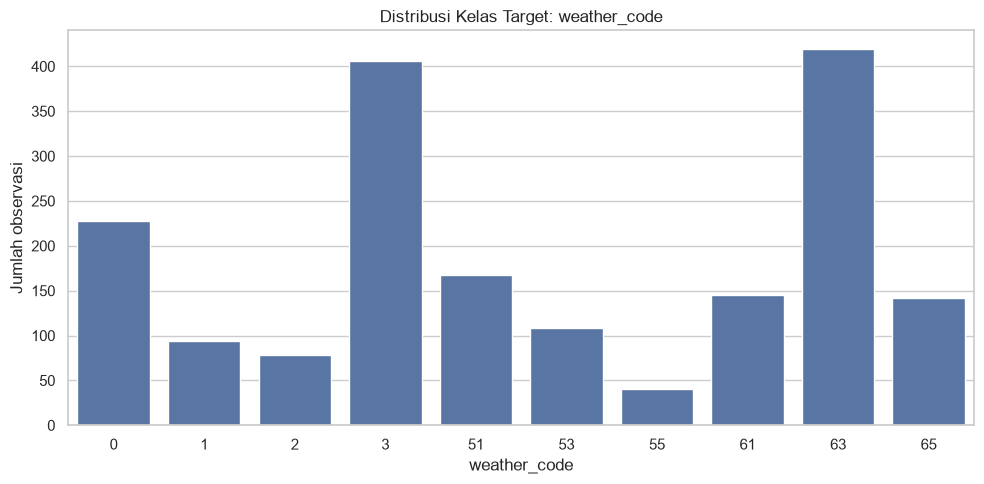

In [26]:
# Distribusi kelas target
plt.figure(figsize=(10, 5))
order = y.value_counts().sort_index().index
sns.countplot(x=y.astype(str), order=[str(v) for v in order])
plt.title("Distribusi Kelas Target: weather_code")
plt.xlabel("weather_code")
plt.ylabel("Jumlah observasi")
plt.tight_layout()
plt.show()

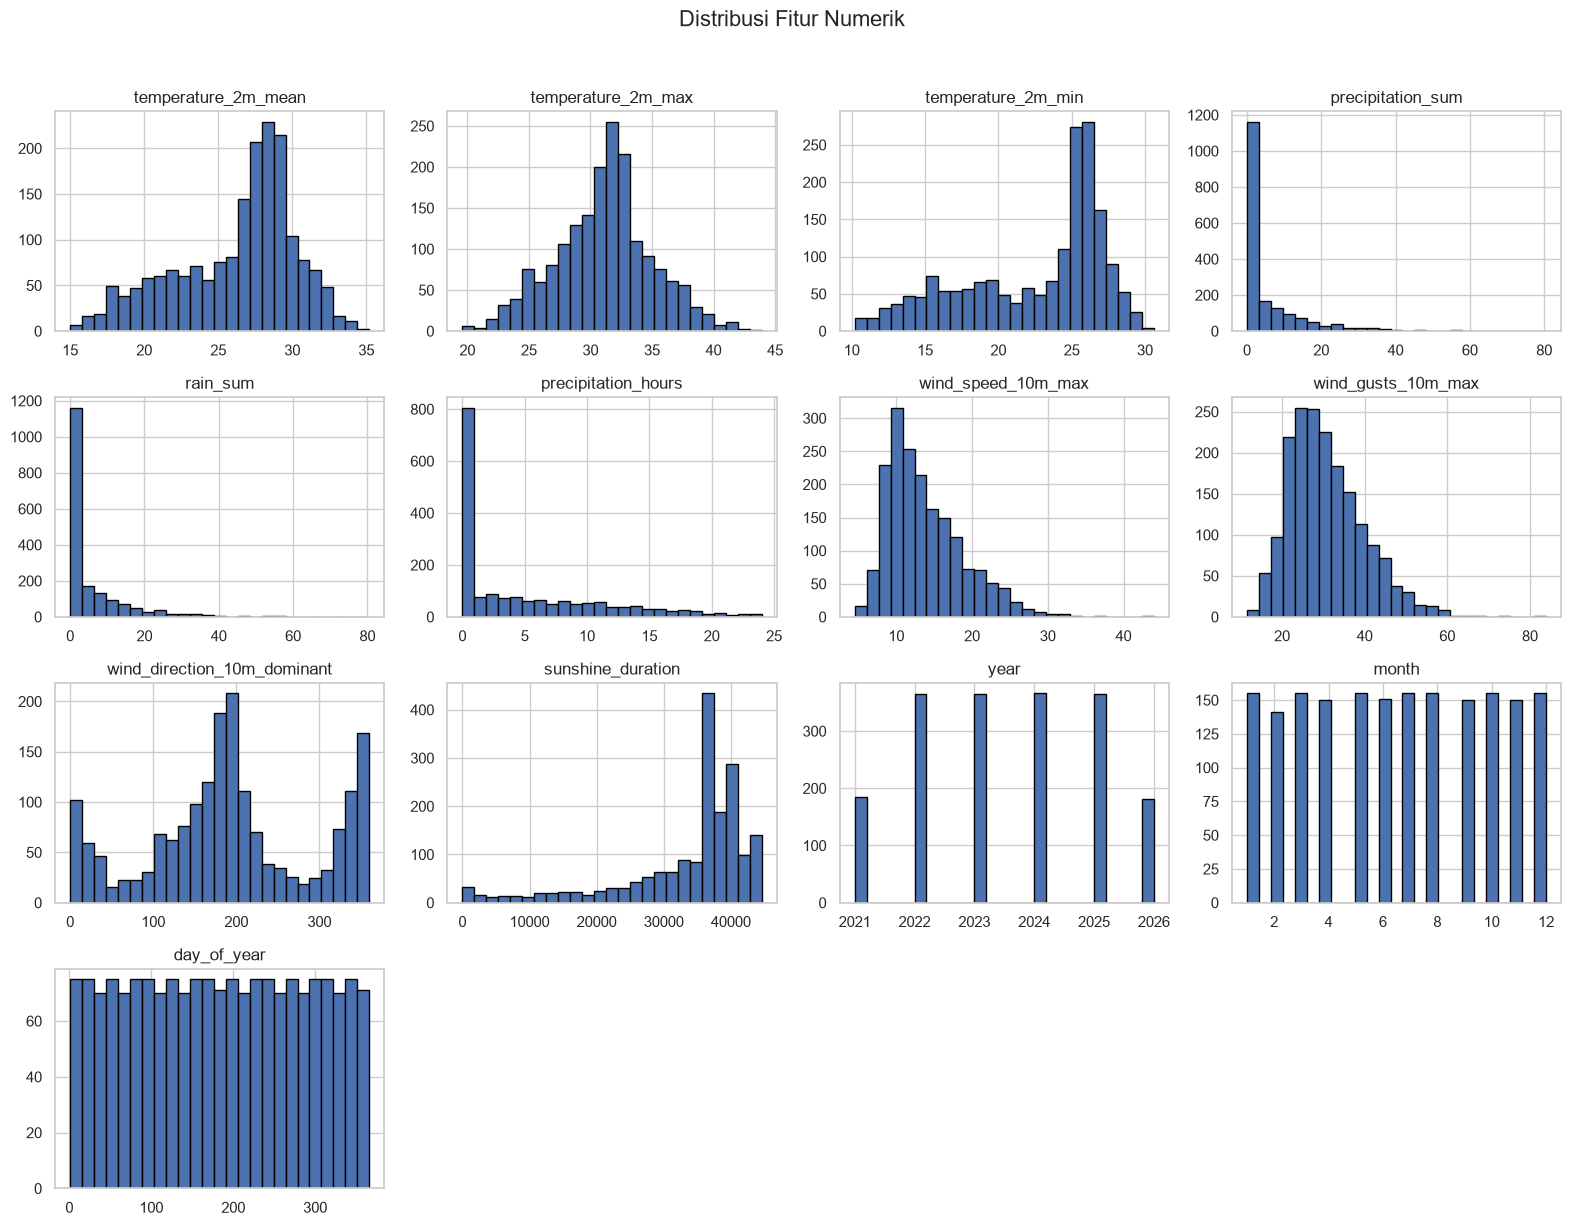

In [27]:
# Histogram fitur numerik
X.hist(figsize=(16, 12), bins=25, edgecolor="black")
plt.suptitle("Distribusi Fitur Numerik", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

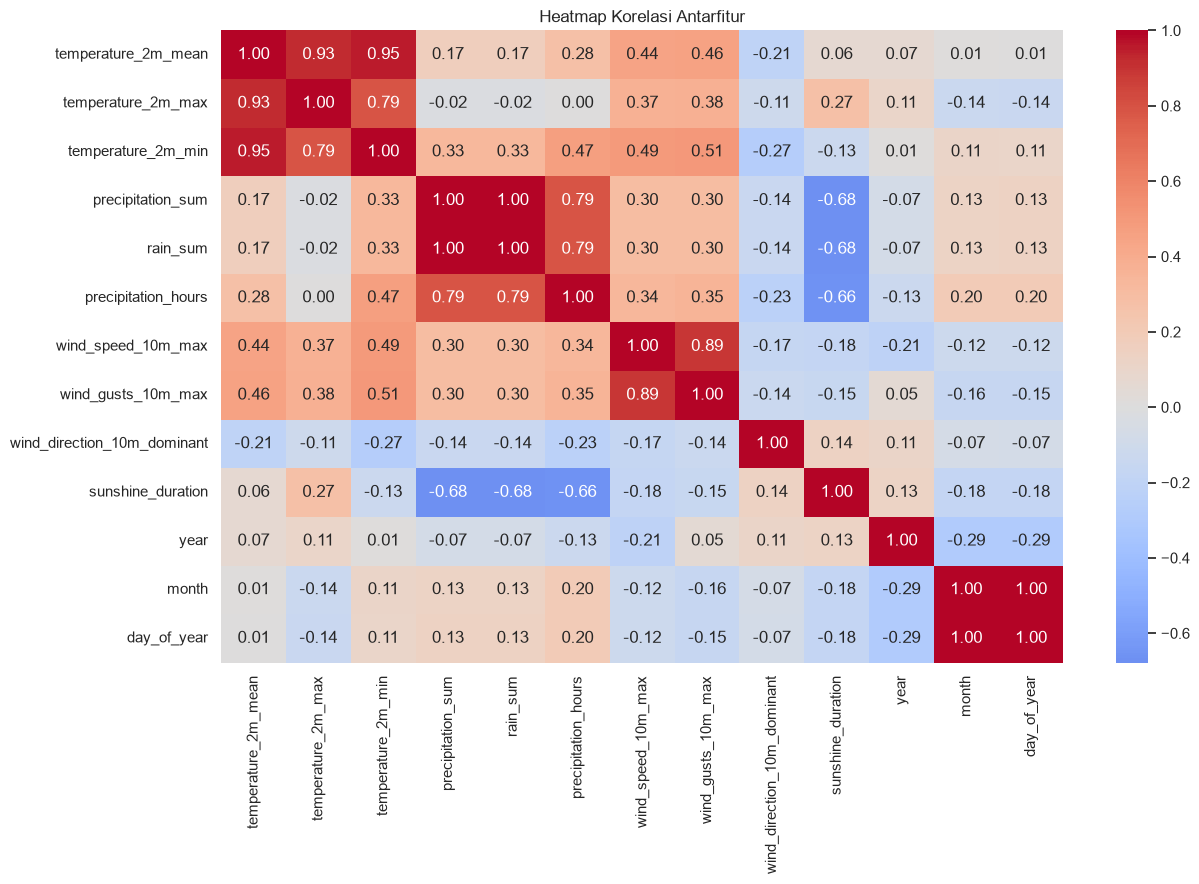

In [28]:
# Heatmap korelasi fitur
plt.figure(figsize=(13, 9))
corr = X.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Heatmap Korelasi Antarfitur")
plt.tight_layout()
plt.show()

In [29]:
print("Missing values pada fitur:")
display(X.isna().sum().rename("missing_values").to_frame())
print("Jumlah duplikat:", data.duplicated().sum())

Missing values pada fitur:


,missing_values
temperature_2m_mean,0
temperature_2m_max,0
temperature_2m_min,0
precipitation_sum,0
rain_sum,0
precipitation_hours,0
wind_speed_10m_max,0
wind_gusts_10m_max,0
wind_direction_10m_dominant,0
sunshine_duration,0


Jumlah duplikat: 0


In [30]:
# X berisi fitur numerik; nilai kosong diimputasi menggunakan median.
# Tidak ada encoding kategorikal yang diperlukan pada fitur yang dipilih.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)
print("Proporsi train:", round(len(X_train) / len(X) * 100, 2), "%")
print("Proporsi test :", round(len(X_test) / len(X) * 100, 2), "%")

preprocessor = SimpleImputer(strategy="median")
X_train_processed = pd.DataFrame(
    preprocessor.fit_transform(X_train),
    columns=feature_cols,
    index=X_train.index
)
X_test_processed = pd.DataFrame(
    preprocessor.transform(X_test),
    columns=feature_cols,
    index=X_test.index
)

Ukuran X_train: (1461, 13)
Ukuran X_test : (366, 13)
Proporsi train: 79.97 %
Proporsi test : 20.03 %


In [31]:
# XGBoost membutuhkan label kelas berupa integer berurutan untuk objective multikelas.
# Simpan pemetaan agar prediksi bisa dikembalikan ke kode weather_code asli.
classes = np.sort(y_train.unique())
class_to_int = {label: idx for idx, label in enumerate(classes)}
int_to_class = {idx: label for label, idx in class_to_int.items()}

y_train_enc = y_train.map(class_to_int)
y_test_enc = y_test.map(class_to_int)

model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    objective="multi:softprob",
    num_class=len(classes),
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model.fit(X_train_processed, y_train_enc)
y_pred_enc = model.predict(X_test_processed).astype(int)
y_proba = model.predict_proba(X_test_processed)

y_pred = pd.Series([int_to_class[i] for i in y_pred_enc], index=y_test.index, name="prediksi")
print("Pelatihan selesai.")

Pelatihan selesai.


In [32]:
accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)

precision_weighted = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall_weighted = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average="weighted", zero_division=0)

try:
    roc_auc_ovr_macro = roc_auc_score(
        y_test_enc, y_proba,
        multi_class="ovr",
        average="macro",
        labels=np.arange(len(classes))
    )
except ValueError:
    roc_auc_ovr_macro = np.nan

metrics_df = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)",
               "Precision (weighted)", "Recall (weighted)", "F1-score (weighted)", "ROC-AUC OvR (macro)"],
    "Nilai": [accuracy, precision_macro, recall_macro, f1_macro,
              precision_weighted, recall_weighted, f1_weighted, roc_auc_ovr_macro]
})
display(metrics_df.style.format({"Nilai": "{:.4f}"}))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

,Metrik,Nilai
0,Accuracy,0.6284
1,Precision (macro),0.5384
2,Recall (macro),0.4973
3,F1-score (macro),0.4955
4,Precision (weighted),0.6035
5,Recall (weighted),0.6284
6,F1-score (weighted),0.6032
7,ROC-AUC OvR (macro),0.9334



Classification report:
              precision    recall  f1-score   support

           0       0.48      0.63      0.54        46
           1       0.33      0.05      0.09        19
           2       0.17      0.06      0.09        16
           3       0.61      0.69      0.65        81
          51       0.93      0.85      0.89        33
          53       0.64      0.82      0.72        22
          55       0.33      0.12      0.18         8
          61       0.58      0.48      0.53        29
          63       0.71      0.83      0.77        84
          65       0.60      0.43      0.50        28

    accuracy                           0.63       366
   macro avg       0.54      0.50      0.50       366
weighted avg       0.60      0.63      0.60       366



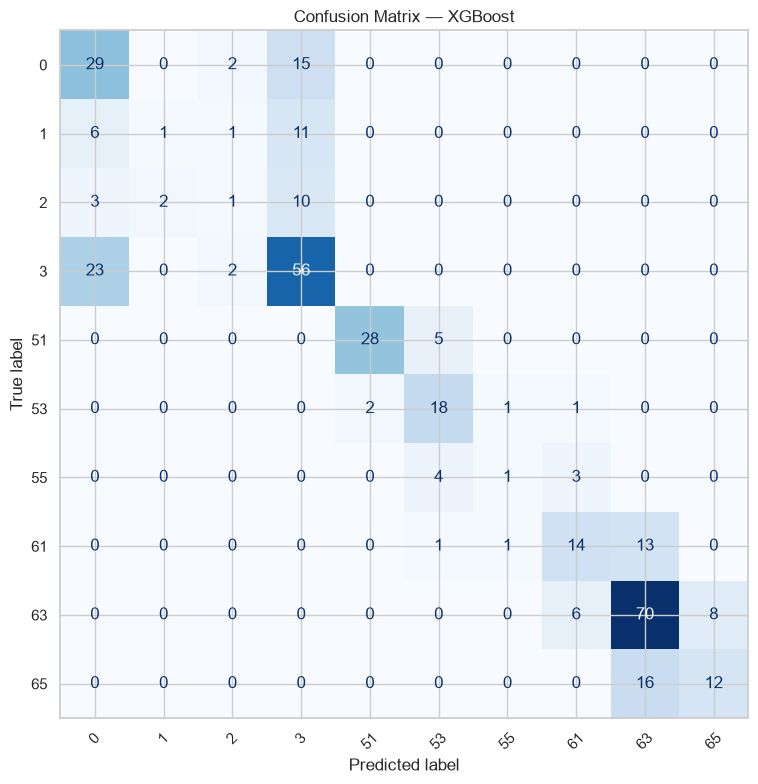

In [33]:
labels_sorted = sorted(pd.unique(y_test).tolist())
cm = confusion_matrix(y_test, y_pred, labels=labels_sorted)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_sorted)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("Confusion Matrix — XGBoost")
plt.tight_layout()
plt.show()

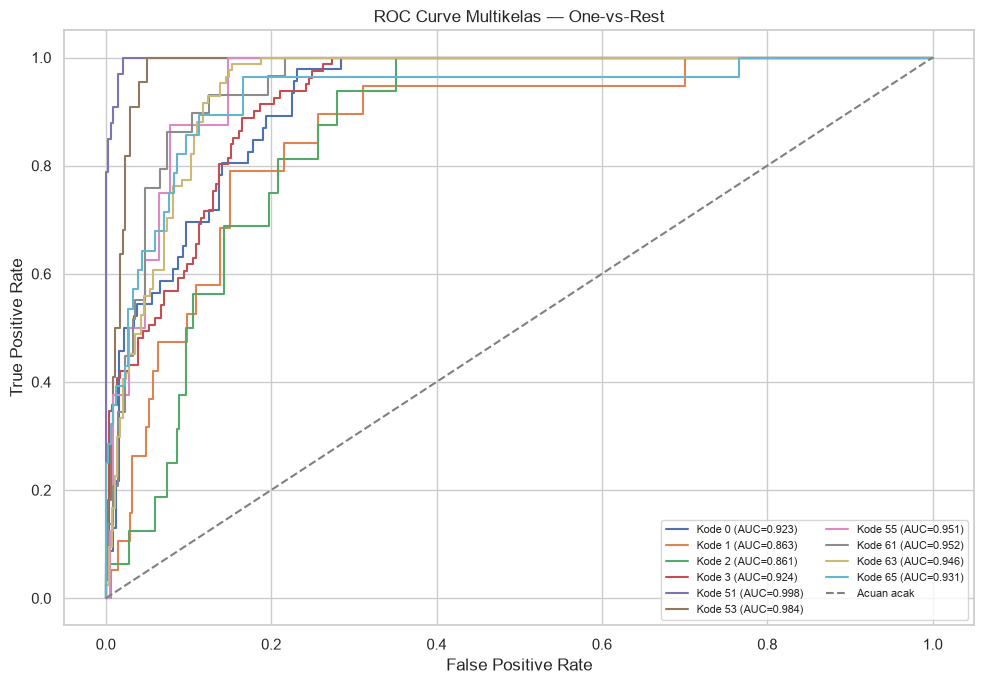

,weather_code,ROC_AUC
0,0,0.922962
1,1,0.863037
2,2,0.861429
3,3,0.924323
4,51,0.997816
5,53,0.983747
6,55,0.951466
7,61,0.951806
8,63,0.946429
9,65,0.931002


In [34]:
y_test_bin = label_binarize(y_test_enc, classes=np.arange(len(classes)))
fig, ax = plt.subplots(figsize=(10, 7))
roc_auc_per_class = {}

for i, original_class in enumerate(classes):
    # ROC memerlukan contoh positif dan negatif pada kelas tersebut
    if len(np.unique(y_test_bin[:, i])) < 2:
        continue
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    auc_i = auc(fpr, tpr)
    roc_auc_per_class[original_class] = auc_i
    ax.plot(fpr, tpr, label=f"Kode {original_class} (AUC={auc_i:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Acuan acak")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve Multikelas — One-vs-Rest")
ax.legend(loc="lower right", fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

display(pd.DataFrame(
    [{"weather_code": k, "ROC_AUC": v} for k, v in roc_auc_per_class.items()]
).sort_values("weather_code"))

,Fitur,Importance
3,precipitation_sum,0.440718
5,precipitation_hours,0.083533
9,sunshine_duration,0.079569
2,temperature_2m_min,0.053278
1,temperature_2m_max,0.052908
12,day_of_year,0.047410
8,wind_direction_10m_dominant,0.047048
7,wind_gusts_10m_max,0.043165
6,wind_speed_10m_max,0.042665
10,year,0.038819


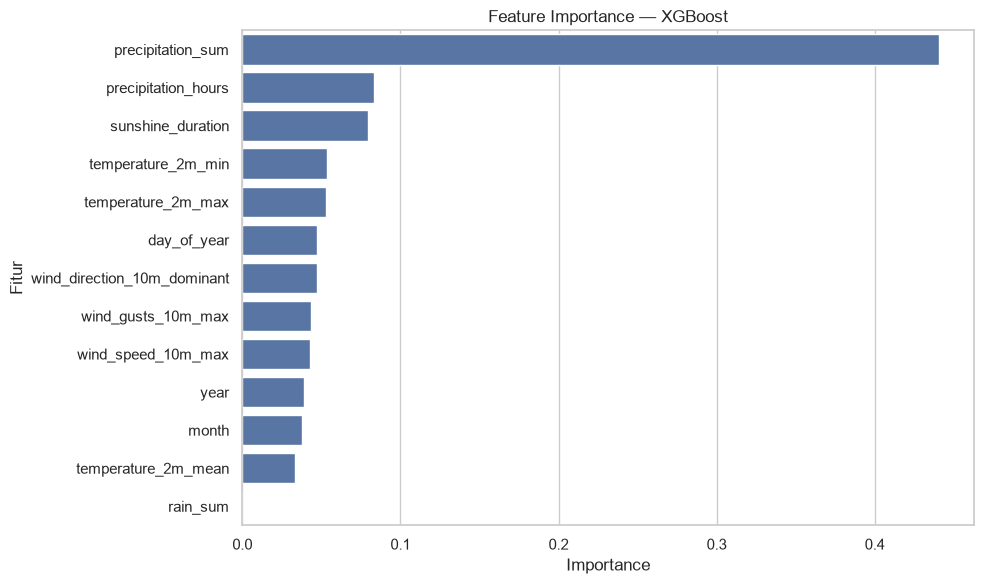

In [35]:
importance_df = pd.DataFrame({
    "Fitur": feature_cols,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df)
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x="Importance", y="Fitur")
plt.title("Feature Importance — XGBoost")
plt.xlabel("Importance")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

In [36]:
manual_input = X.median(numeric_only=True).to_frame().T
manual_input = manual_input[feature_cols]
manual_processed = pd.DataFrame(
    preprocessor.transform(manual_input),
    columns=feature_cols
)
manual_proba = model.predict_proba(manual_processed)[0]
manual_pred_idx = int(np.argmax(manual_proba))
manual_pred_code = int_to_class[manual_pred_idx]

print("Input contoh:")
display(manual_input)
print("Prediksi weather_code:", manual_pred_code)
print("Probabilitas prediksi:", round(float(manual_proba[manual_pred_idx]), 4))

prob_df = pd.DataFrame({
    "weather_code": [int_to_class[i] for i in range(len(manual_proba))],
    "probabilitas": manual_proba
}).sort_values("probabilitas", ascending=False)
display(prob_df)

Input contoh:


,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_duration,year,month,day_of_year
0,27.4,31.3,24.6,0.4,0.4,2.0,12.6,29.5,188.0,36088.15,2023.0,7.0,183.0


Prediksi weather_code: 51
Probabilitas prediksi: 0.9969


,weather_code,probabilitas
4,51,0.996864
0,0,0.000652
3,3,0.000428
5,53,0.000398
8,63,0.000373
7,61,0.000361
2,2,0.000293
1,1,0.000270
9,65,0.000193
6,55,0.000169


In [37]:

# ============================================================
# MENYIMPAN DATASET YANG SUDAH DIBERSIHKAN
# ============================================================

import pandas as pd
import os

# Pastikan variabel data sudah tersedia dari proses preprocessing
# Hapus baris duplikat
data_clean = data.drop_duplicates().copy()

# Hapus baris dengan tanggal atau target yang kosong
data_clean = data_clean.dropna(
    subset=["time", "weather_code"]
).copy()

# Pastikan kolom waktu berformat datetime
data_clean["time"] = pd.to_datetime(
    data_clean["time"],
    errors="coerce"
)

# Hapus baris yang tanggalnya gagal dikonversi
data_clean = data_clean.dropna(subset=["time"]).copy()

# Simpan dataset hasil pembersihan
output_file = "kolkata_weather_cleaned.csv"

data_clean.to_csv(
    output_file,
    index=False,
    encoding="utf-8"
)

print("Dataset berhasil disimpan!")
print("Lokasi file:", os.path.abspath(output_file))
print("Jumlah baris:", data_clean.shape[0])
print("Jumlah kolom:", data_clean.shape[1])

# Tampilkan hasil dataset
display(data_clean.head())


Dataset berhasil disimpan!
Lokasi file: c:\Users\user\Videos\Semester 7\XGBoost\kolkata_weather_cleaned.csv
Jumlah baris: 1827
Jumlah kolom: 20


,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude,year,month,day_of_year
0,2021-06-30,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,2021-06-30T04:55,2021-06-30T18:25,20837.76,Kolkata,22.5726,88.3639,2021,6,181
1,2021-07-01,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,2021-07-01T04:55,2021-07-01T18:25,21439.24,Kolkata,22.5726,88.3639,2021,7,182
2,2021-07-02,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,2021-07-02T04:56,2021-07-02T18:25,12291.52,Kolkata,22.5726,88.3639,2021,7,183
3,2021-07-03,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,2021-07-03T04:56,2021-07-03T18:25,29486.65,Kolkata,22.5726,88.3639,2021,7,184
4,2021-07-04,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,2021-07-04T04:56,2021-07-04T18:25,41145.46,Kolkata,22.5726,88.3639,2021,7,185


In [38]:

# Baca kembali file CSV hasil pembersihan
df_cleaned = pd.read_csv("kolkata_weather_cleaned.csv")

print("Ukuran dataset hasil pembersihan:", df_cleaned.shape)
print("\nMissing values setiap kolom:")
display(df_cleaned.isna().sum().to_frame("Jumlah Missing Values"))

print("\nJumlah data duplikat:", df_cleaned.duplicated().sum())


Ukuran dataset hasil pembersihan: (1827, 20)

Missing values setiap kolom:


,Jumlah Missing Values
time,0
weather_code,0
temperature_2m_mean,0
temperature_2m_max,0
temperature_2m_min,0
precipitation_sum,0
rain_sum,0
precipitation_hours,0
wind_speed_10m_max,0
wind_gusts_10m_max,0



Jumlah data duplikat: 0
